# Introduction

## Data Preprocessing and Dimensionality Reduction

This notebook focuses on preparing the dataset for machine learning by performing the following steps:
- Data preprocessing 
- Dimensionality reduction using **Principal Component Analysis (PCA)**.

# Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# Data Preprocessing

## Data Preprocessing Steps

1. Handling NULL Values
2. Handling duplicated rows
3. Label encoding the target coloumn
4. Standardising the features
5. Applying PCA

In [2]:
columns = [
    "ID", "Diagnosis", "Radius_mean", "Texture_mean", "Perimeter_mean", "Area_mean", "Smoothness_mean", 
    "Compactness_mean", "Concavity_mean", "Concave_points_mean", "Symmetry_mean", "Fractal_dimension_mean",
    "Radius_se", "Texture_se", "Perimeter_se", "Area_se", "Smoothness_se", "Compactness_se", "Concavity_se",
    "Concave_points_se", "Symmetry_se", "Fractal_dimension_se", "Radius_worst", "Texture_worst", "Perimeter_worst",
    "Area_worst", "Smoothness_worst", "Compactness_worst", "Concavity_worst", "Concave_points_worst",
    "Symmetry_worst", "Fractal_dimension_worst"
]
data = pd.read_csv("wdbc.data",header=None, names=columns)
data = data.drop("ID", axis=1) #ID coloumn is not useful

In [3]:
data.isnull().sum() #Checking for null values

Diagnosis                  0
Radius_mean                0
Texture_mean               0
Perimeter_mean             0
Area_mean                  0
Smoothness_mean            0
Compactness_mean           0
Concavity_mean             0
Concave_points_mean        0
Symmetry_mean              0
Fractal_dimension_mean     0
Radius_se                  0
Texture_se                 0
Perimeter_se               0
Area_se                    0
Smoothness_se              0
Compactness_se             0
Concavity_se               0
Concave_points_se          0
Symmetry_se                0
Fractal_dimension_se       0
Radius_worst               0
Texture_worst              0
Perimeter_worst            0
Area_worst                 0
Smoothness_worst           0
Compactness_worst          0
Concavity_worst            0
Concave_points_worst       0
Symmetry_worst             0
Fractal_dimension_worst    0
dtype: int64

In [4]:
data.duplicated().sum() #Checking if there are duplicated values

np.int64(0)

In [5]:
#Label encoding target coloumnn
data["Diagnosis"] = data["Diagnosis"].map({"B": 0, "M": 1})

In [6]:
#Split the dataset
X = data.drop('Diagnosis', axis=1)
y = data['Diagnosis']

In [7]:
#Standardise features
scaler = StandardScaler()
X = scaler.fit_transform(X)

## Applying Principal Component Analysis (PCA)

PCA is applied to reduce the dimensionality of the dataset. Key steps:
1. **Fit and Transform**: The PCA algorithm is applied to the standardized dataset.
2. **Variance Explained**: Each principal component is ranked by the amount of variance it explains. This helps identify the optimal number of components.

In [8]:
#Get 15 principal components
pca = PCA(n_components=15)  
X_pca = pca.fit_transform(X)

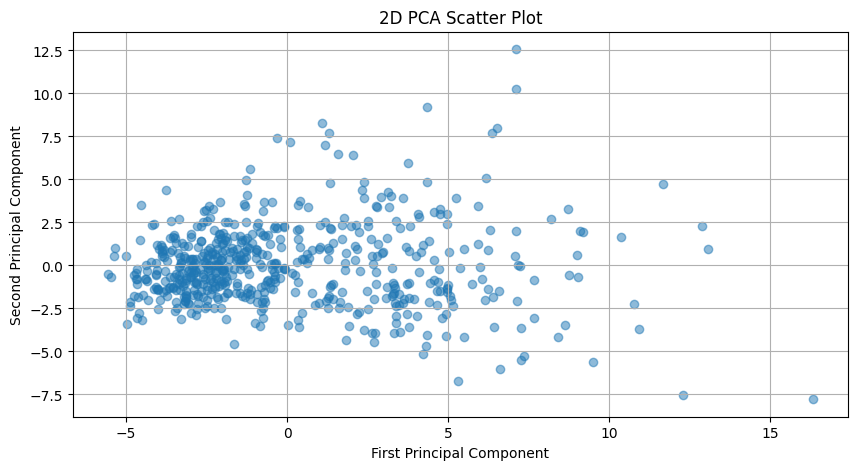

In [9]:
#2D Scatter Plot of the First Two PCs
plt.figure(figsize=(10, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.5)
plt.title('2D PCA Scatter Plot')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.grid()
plt.show()

- This plot shows the data points plotted along the first and second principal component.
- Clearly the data is more spread out along the first principal component, showing that it captures more variance.

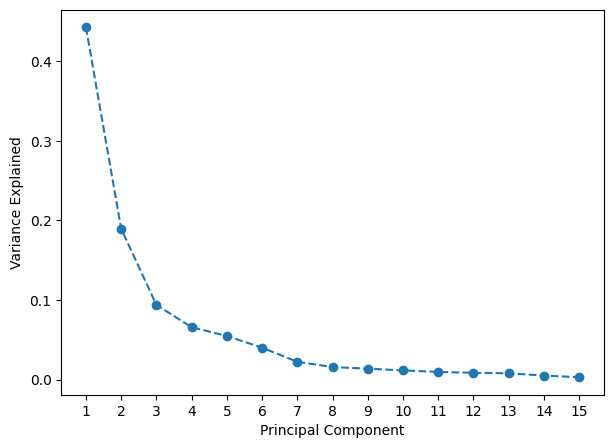

In [10]:
#Variance captured by each PC
explained_variance = pca.explained_variance_ratio_ 
plt.figure(figsize=(7, 5))
plt.plot(range(1, len(explained_variance) + 1), explained_variance, marker='o', linestyle='--')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.xticks(range(1, len(explained_variance) + 1))
plt.show()

- This plot shows the variance explained by each principal component.
- The goal is to identify the "elbow point," where adding more components yields diminishing returns in terms of variance explained.
- An elbow occurs at 3. Hence, we can retain the first three principal components.

In [11]:
#Retaining only the first 3 PCs 
X_pca = X_pca[:, :3]